In [ ]:
import os
# os.environ["TF_USE_LEGACY_KERAS"] = "1"
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
# from tensorflow import keras
import matplotlib.pyplot as plt
import cv2
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
keras.utils.set_random_seed(2024)

In [ ]:
IMAGE_SHAPE= (224, 224, 3)
PREFIX = '/kaggle/input/better-mura/MURA-v1.1/'
TRAIN_PATH = "/kaggle/input/better-mura/MURA-v1.1/MURA-v1.1/train_augmented.csv"
TEST_PATH = "/kaggle/input/better-mura/MURA-v1.1/MURA-v1.1/valid.csv"

In [ ]:
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

In [ ]:


import os
import sys
from tempfile import NamedTemporaryFile
from urllib.request import urlopen
from urllib.parse import unquote, urlparse
from urllib.error import HTTPError
from zipfile import ZipFile
import tarfile
import shutil

CHUNK_SIZE = 40960
DATA_SOURCE_MAPPING = 'mura-v11:https%3A%2F%2Fstorage.googleapis.com%2Fkaggle-data-sets%2F427555%2F813639%2Fbundle%2Farchive.zip%3FX-Goog-Algorithm%3DGOOG4-RSA-SHA256%26X-Goog-Credential%3Dgcp-kaggle-com%2540kaggle-161607.iam.gserviceaccount.com%252F20241007%252Fauto%252Fstorage%252Fgoog4_request%26X-Goog-Date%3D20241007T131333Z%26X-Goog-Expires%3D259200%26X-Goog-SignedHeaders%3Dhost%26X-Goog-Signature%3Da8542e935d7abd2f33b5ed2b08f4b51663322b28d7b50635093ff86e8382b6424dbc621ccfc5dbd699e57351d5ce6d3860a0ea45447c0bb2c19f71ffcdab5f0892adba4f87d5f0503e67d3879341deb1044e30a6701ed84da52a8541cbecfcc8b9c5c2965ce42f635248c22112405f88cdc2d617ca7adc0018a69f4dec696053a0c72882a84ec0e1b9489c726008807a3d6bd670772c0cd2b56de8767b8f4e032f9fe5b99129ee6dfeb2aad0cbed2342bdc97344709a2dbae8bcd8dcff2a113146b4bbfa477f620896c3c5ce2324b5c269b930f6617c72788b3e1f5723777119912cf9b28daab4c8a92b986a3740c3a7a2df156e43ab3385694967110f719c17,better-mura:https%3A%2F%2Fstorage.googleapis.com%2Fkaggle-data-sets%2F4358814%2F7921122%2Fbundle%2Farchive.zip%3FX-Goog-Algorithm%3DGOOG4-RSA-SHA256%26X-Goog-Credential%3Dgcp-kaggle-com%2540kaggle-161607.iam.gserviceaccount.com%252F20241007%252Fauto%252Fstorage%252Fgoog4_request%26X-Goog-Date%3D20241007T131333Z%26X-Goog-Expires%3D259200%26X-Goog-SignedHeaders%3Dhost%26X-Goog-Signature%3D5189d35ffe78da9e91204ee081f348ff7cd09f6f8a1c4c553a772f16845f28f18c4a8f508cb073afd480aa0f37c03f3d86cf93e71369b318081421c821c98079a4a870bb66ff69b82cb86e3bd7d63e99f974bc21ff6087f3f8af3f01ab191f0d2a4569dbe9ed9f4bc20c6b91bb9a9e3b15d101b68b9a3345c443da8c18bcc7b7f4b4b4501d2a2f077b06ead24ca77cf810a964352d18197c8e2cd50e4a85128db13ae43cfe6caf3e8fbdf39f0bd07be8cbce801d40c28eccb9f83360a898fa7e27c8248b14e8fef6e39ee2bb0097197d72e6f815b7583b0e433030083007054d38df29b0545601648cff9b168b1a837dbc8110ee7d5153dd14e36ac3c6813712,wrist-mura/keras/effnet/1:https%3A%2F%2Fstorage.googleapis.com%2Fkaggle-models-data%2F27171%2F32459%2Fbundle%2Farchive.tar.gz%3FX-Goog-Algorithm%3DGOOG4-RSA-SHA256%26X-Goog-Credential%3Dgcp-kaggle-com%2540kaggle-161607.iam.gserviceaccount.com%252F20241007%252Fauto%252Fstorage%252Fgoog4_request%26X-Goog-Date%3D20241007T131333Z%26X-Goog-Expires%3D259200%26X-Goog-SignedHeaders%3Dhost%26X-Goog-Signature%3D17e3032f6378bb196ba0f75182c3093c0a0cef8a8165d1053d438badbacbfba98ad3fb95d56f2b2e6ee2bd4223a84e3bb5fc3d8273b97cd40fec56f95f52e9ae47c78d205e8fe0bc3d6f50c60bcca6e1ad990ce5668c5adfe9681a99621750a65b57f4f9fe83a380b866e4b5943b007028559f7d83f3b5c192b5eee6083fde73638c5e56f57300ccc0e7f856b91689dd67856d144c2748d220e1d7cd7160a1c46701c6d1cac62ef0e08c126bbf9cd0e4231c9bec2ea89b33d6e9b42dc6e0f2bc83841d2727a90a7718cf1aa875e0a038289553e12b2d3a90bf26942090e07b69022423afdcb9ca1c6b836545f0320c74af693f0503f27140e7fd0a1c760d23e7'

KAGGLE_INPUT_PATH='/kaggle/input'
KAGGLE_WORKING_PATH='/kaggle/working'
KAGGLE_SYMLINK='kaggle'

!umount /kaggle/input/ 2> /dev/null
shutil.rmtree('/kaggle/input', ignore_errors=True)
os.makedirs(KAGGLE_INPUT_PATH, 0o777, exist_ok=True)
os.makedirs(KAGGLE_WORKING_PATH, 0o777, exist_ok=True)

try:
  os.symlink(KAGGLE_INPUT_PATH, os.path.join("..", 'input'), target_is_directory=True)
except FileExistsError:
  pass
try:
  os.symlink(KAGGLE_WORKING_PATH, os.path.join("..", 'working'), target_is_directory=True)
except FileExistsError:
  pass

for data_source_mapping in DATA_SOURCE_MAPPING.split(','):
    directory, download_url_encoded = data_source_mapping.split(':')
    download_url = unquote(download_url_encoded)
    filename = urlparse(download_url).path
    destination_path = os.path.join(KAGGLE_INPUT_PATH, directory)
    try:
        with urlopen(download_url) as fileres, NamedTemporaryFile() as tfile:
            total_length = fileres.headers['content-length']
            print(f'Downloading {directory}, {total_length} bytes compressed')
            dl = 0
            data = fileres.read(CHUNK_SIZE)
            while len(data) > 0:
                dl += len(data)
                tfile.write(data)
                done = int(50 * dl / int(total_length))
                sys.stdout.write(f"\r[{'=' * done}{' ' * (50-done)}] {dl} bytes downloaded")
                sys.stdout.flush()
                data = fileres.read(CHUNK_SIZE)
            if filename.endswith('.zip'):
              with ZipFile(tfile) as zfile:
                zfile.extractall(destination_path)
            else:
              with tarfile.open(tfile.name) as tarfile:
                tarfile.extractall(destination_path)
            print(f'\nDownloaded and uncompressed: {directory}')
    except HTTPError as e:
        print(f'Failed to load (likely expired) {download_url} to path {destination_path}')
        continue
    except OSError as e:
        print(f'Failed to load {download_url} to path {destination_path}')
        continue

print('Data source import complete.')


[==================================================] 3374985543 bytes downloaded
Downloaded and uncompressed: mura-v11
[==================================================] 7130265898 bytes downloaded
Downloaded and uncompressed: better-mura
[==================================================] 133131166 bytes downloaded
Downloaded and uncompressed: wrist-mura/keras/effnet/1
Data source import complete.


In [ ]:
print(len(df_train), len(df_test))

220848 3197


In [ ]:
df_train.head()

,path,label,BodyPart,diagnosis,bodypart_lable
0,MURA-v1.1/train_augmented/XR_SHOULDER/patient0...,1,XR_SHOULDER,fracture_in_shoulder,5
1,MURA-v1.1/train_augmented/XR_SHOULDER/patient0...,1,XR_SHOULDER,fracture_in_shoulder,5
2,MURA-v1.1/train_augmented/XR_SHOULDER/patient0...,1,XR_SHOULDER,fracture_in_shoulder,5
3,MURA-v1.1/train_augmented/XR_SHOULDER/patient0...,1,XR_SHOULDER,fracture_in_shoulder,5
4,MURA-v1.1/train_augmented/XR_SHOULDER/patient0...,1,XR_SHOULDER,fracture_in_shoulder,5


In [ ]:
df_train['BodyPart'].value_counts()

,count
BodyPart,
XR_WRIST,58512
XR_SHOULDER,50274
XR_HAND,33258
XR_FINGER,30636
XR_ELBOW,29586
XR_FOREARM,10950
XR_HUMERUS,7632


In [ ]:
df_train_wrest = df_train[df_train['BodyPart'] == 'XR_ELBOW'].reset_index(drop = True)[['path', 'label']]
df_test_wrest = df_test[df_test['BodyPart'] == 'XR_ELBOW'].reset_index(drop = True)[['path', 'label']]

In [ ]:
df_train_wrest.head()

,path,label
0,MURA-v1.1/train_augmented/XR_ELBOW/patient0490...,1
1,MURA-v1.1/train_augmented/XR_ELBOW/patient0490...,1
2,MURA-v1.1/train_augmented/XR_ELBOW/patient0490...,1
3,MURA-v1.1/train_augmented/XR_ELBOW/patient0490...,1
4,MURA-v1.1/train_augmented/XR_ELBOW/patient0490...,1


In [ ]:
df_train_wrest['label'].value_counts()

,count
label,
0,17160
1,12426


In [ ]:
def create_tf_dataset(df):
    df = df.sample(frac=1).reset_index(drop=True)
    imgs, labels = tf.convert_to_tensor(df['path']), tf.convert_to_tensor(df['label'])
    ds = tf.data.Dataset.from_tensor_slices((imgs, labels))
    return ds

In [ ]:
ds_raw = create_tf_dataset(df_train_wrest)
test_raw  = create_tf_dataset(df_test_wrest)

In [ ]:
TRAIN_SIZE = int(len(df_train_wrest) * 0.9)

ds_raw = ds_raw.shuffle(10000)
train_raw = ds_raw.take(TRAIN_SIZE)
valid_raw = ds_raw.skip(TRAIN_SIZE)

In [ ]:
len(train_raw), len(valid_raw)

(26627, 2959)

In [ ]:
train_raw.element_spec

(TensorSpec(shape=(), dtype=tf.string, name=None),
 TensorSpec(shape=(), dtype=tf.int64, name=None))

In [ ]:
for ex_path, ex_label in train_raw.skip(1).take(1):
    print(ex_path)
    print(ex_label)

tf.Tensor(b'MURA-v1.1/train_augmented/XR_ELBOW/patient05764/study1_negative/image3_aug_4_Blur.jpg', shape=(), dtype=string)
tf.Tensor(0, shape=(), dtype=int64)


In [ ]:
def load_image(image_path):
    img = tf.io.read_file(PREFIX + image_path)
    img = tf.io.decode_png(img, channels=3)
    img = tf.image.resize(img, IMAGE_SHAPE[:-1])
    return img

(224, 224, 3)


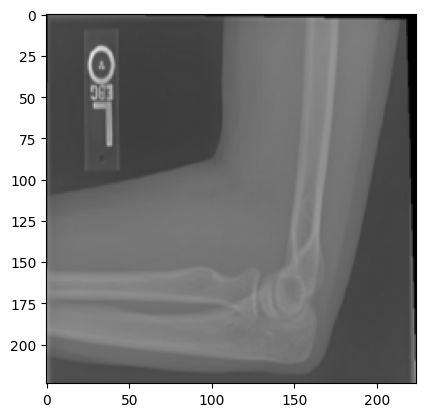

In [ ]:
test_img = load_image(ex_path)
print(test_img.shape)
plt.imshow(test_img.numpy().astype('uint8'));

In [ ]:
def apply_CLAHE(img):
    t_img = img.numpy().astype('uint8')
    gray = cv2.cvtColor(t_img, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8, 8))
    clahe_img = clahe.apply(gray)
    clahe_img_colored = cv2.cvtColor(clahe_img, cv2.COLOR_GRAY2RGB)
    return tf.convert_to_tensor(clahe_img_colored, dtype=tf.float32)

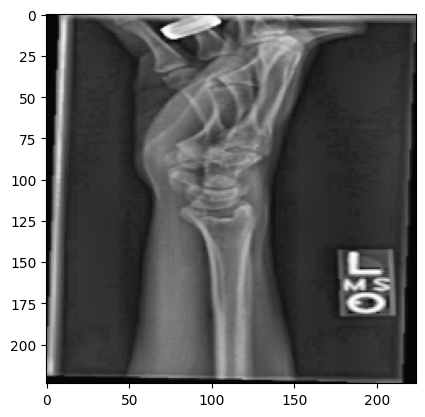

In [ ]:
clahe_image = apply_CLAHE(test_img)
plt.imshow(clahe_image.numpy().astype('uint8'));

In [ ]:
def prepare_dataset(ds, batch_size=32, shuffle_buffer=10000, shuffle = False):
    if shuffle:
        ds = ds.shuffle(shuffle_buffer)

    return (ds.
        map(lambda path, label: (load_image(path), tf.expand_dims(label, 0)), tf.data.AUTOTUNE).
        apply(tf.data.experimental.ignore_errors()).
        batch(batch_size).
        prefetch(tf.data.AUTOTUNE)
       )

In [ ]:
train_ds = prepare_dataset(train_raw, shuffle = True)
valid_ds = prepare_dataset(valid_raw)
test_ds = prepare_dataset(test_raw)
train_ds.element_spec

Instructions for updating:
Use `tf.data.Dataset.ignore_errors` instead.


(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
 TensorSpec(shape=(None, 1), dtype=tf.int64, name=None))

In [ ]:
for img, label in train_ds.take(1):
    print(img.shape, tf.squeeze(label))

(32, 224, 224, 3) tf.Tensor([0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0], shape=(32,), dtype=int64)


## Modelling

In [ ]:
from keras.applications import vgg19, densenet, efficientnet, efficientnet_v2

In [ ]:
# Displaying history loss/accuracy
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
def plot_his(history):
    plt.figure(figsize=(15,12))
    metrics = ['accuracy', 'loss']
    for i, metric in enumerate(metrics):
        plt.subplot(220+1+i)
        plt.plot(history.epoch, history.history[metric], color=colors[0], label='Train')
        plt.plot(history.epoch, history.history['val_'+metric],
                 color=colors[1], linestyle="--", label='Val')
        plt.xlabel('Epoch')
        plt.ylabel(metric)
        plt.legend()
    plt.show()

def print_results(model):
    train_res, valid_res, test_res = model.evaluate(train_ds.take(100), verbose = 0), model.evaluate(valid_ds.take(100), verbose = 0), model.evaluate(test_ds, verbose = 0)
    print("Train Loss     : {0:.5f}".format(train_res[2]))
    print("Validation Loss: {0:.5f}".format(valid_res[2]))
    print("test Loss: {0:.5f}".format(test_res[2]))
    print("---")
    print("Train Accuracy     : {0:.5f}".format(train_res[1]))
    print("Validation Accuracy: {0:.5f}".format(valid_res[1]))
    print("Test Accuracy: {0:.5f}".format(test_res[1]))

def plot_conf_matrix(model):
    y_test = np.concatenate([y for x, y in test_ds], axis=0)

    y_pred = np.round(model.predict(test_ds))

    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, vmin=0, fmt='g', cmap='Blues', cbar=False)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix")
    plt.show()

In [ ]:
@keras.saving.register_keras_serializable()
class CLAHE(keras.layers.Layer):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def call(self, inputs, active = True):
        # THIS WRAPPER IS MANDATORY TO SET THE SHAPE OF THE OUTPUT TENSOR
        # https://stackoverflow.com/questions/42590431/output-from-tensorflow-py-func-has-unknown-rank-shape
        def tf_wrapper(img):
            @tf.py_function(Tout=tf.float32)
            def apply_CLAHE(img):
                t_img = img.numpy().astype('uint8')
                gray = cv2.cvtColor(t_img, cv2.COLOR_BGR2GRAY)
                clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8, 8))
                clahe_img = clahe.apply(gray)
                clahe_img_colored = cv2.cvtColor(clahe_img, cv2.COLOR_GRAY2RGB)
                return tf.convert_to_tensor(clahe_img_colored, dtype=tf.float32)
            new_img = apply_CLAHE(img)
            new_img.set_shape(img.shape)
            return new_img

        _ndims = inputs.get_shape().ndims
        if active == True:
            if _ndims == 3:
                return tf_wrapper(inputs)
            elif _ndims == 4:
                return tf.map_fn(tf_wrapper, inputs)
        else:
            return inputs

@keras.saving.register_keras_serializable()
class WristMURA(keras.Model):
    def __init__(self,
                 preprocess_fn,
                 base_model,
                 apply_CLAHE,
                 apply_aug,
                 top_layers_trainable,
                 top_layers_trainable_num,
                 trainable=True,
                 name=None,
                 dtype=None
                ):
        super().__init__(trainable=trainable, name=name, dtype=dtype)

        self.preprocess_fn = preprocess_fn

        # Model layers
        self.clahe_layer = CLAHE()
        self.data_augmentation = keras.Sequential([
          keras.layers.RandomFlip("horizontal"),
          keras.layers.RandomRotation(0.2),
        ])

        self.base_model = base_model
        self.dense1_layer = keras.layers.Dense(512, kernel_regularizer=keras.regularizers.L2(1e-4), activation = 'relu', name="Dense_layer_1")
        self.dropout1_layer = keras.layers.Dropout(.4, name="Dropout_layer_1")
        self.dense2_layer = keras.layers.Dense(256, kernel_regularizer=keras.regularizers.L2(1e-4), activation = 'relu', name="Dense_layer_2")
        self.dropout2_layer = keras.layers.Dropout(.4, name="Dropout_layer_2")
        self.output_layer = keras.layers.Dense(1, activation='sigmoid', name="Output_layer")

        # Model configs
        self.base_model.trainable = False

        self.apply_CLAHE = apply_CLAHE
        self.apply_aug = apply_aug

        self.top_layers_trainable_num = top_layers_trainable_num
        self.top_layers_trainable = top_layers_trainable


    def call(self, inputs, training=None):

        inputs = self.clahe_layer(inputs, active=self.apply_CLAHE)
        inputs = self.data_augmentation(inputs, training=(self.apply_aug and training))

        inputs = self.preprocess_fn(inputs)

        x = self.base_model(inputs, training=training)
        x = self.dense1_layer(x)
        x = self.dropout1_layer(x, training=training)
        x = self.dense2_layer(x)
        x = self.dropout2_layer(x, training=training)

        output = self.output_layer(x)

        return output


    @property
    def top_layers_trainable(self):
        return self._top_layers_trainable

    @top_layers_trainable.setter
    def top_layers_trainable(self, value):
        self._top_layers_trainable = value
        if value == True:
            self.base_model.trainable = True
            for layer in self.base_model.layers[:-self.top_layers_trainable_num]:
                  layer.trainable=False
        else:
            self.base_model.trainable = False

#     def build(self, input_shape):
#         x = keras.layers.Input(input_shape)

#         layers = []
#         if self.apply_CLAHE == True:
#             layers += [self.clahe_layer]
#         if self.apply_aug:
#             layers += [self.data_augmentation]

#         layers += [self.base_model, self.dense1_layer, self.dropout1_layer,
#                   self.dense2_layer,self.dropout2_layer, self.output_layer]
#         for layer in layers:
#             x = layer(x)

    def get_config(self):
        base_config = super().get_config()
        config = {
            "preprocess_fn": keras.saving.serialize_keras_object(self.preprocess_fn),
            "base_model": keras.saving.serialize_keras_object(self.base_model),
            "apply_CLAHE": keras.saving.serialize_keras_object(self.apply_CLAHE),
            "apply_aug": keras.saving.serialize_keras_object(self.apply_aug),
            "top_layers_trainable": keras.saving.serialize_keras_object(self.top_layers_trainable),
            "top_layers_trainable_num": keras.saving.serialize_keras_object(self.top_layers_trainable_num),
        }
        return {**base_config, **config}

    @classmethod
    def from_config(cls, config, custom_objects=None):
        config['preprocess_fn'] = keras.saving.deserialize_keras_object(config['preprocess_fn'])
        config['base_model'] = keras.saving.deserialize_keras_object(config['base_model'])
        config['apply_CLAHE'] = keras.saving.deserialize_keras_object(config['apply_CLAHE'])
        config['apply_aug'] = keras.saving.deserialize_keras_object(config['apply_aug'])
        config['top_layers_trainable'] = keras.saving.deserialize_keras_object(config['top_layers_trainable'])
        config['top_layers_trainable_num'] = keras.saving.deserialize_keras_object(config['top_layers_trainable_num'])
        return cls(**config)

----
# Training

In [ ]:
@keras.saving.register_keras_serializable()
def preprocess_fn_wrapper(x):
    return efficientnet_v2.preprocess_input(x)

In [ ]:
model = WristMURA(
    preprocess_fn=preprocess_fn_wrapper,
    base_model=efficientnet_v2.EfficientNetV2B3(include_top=False, pooling='avg'),
    top_layers_trainable=True,
    apply_CLAHE=True,
    apply_aug=False,
    top_layers_trainable_num=200
)

52606240/52606240 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
STEPS_PER_EPOCH = 150

lr_schedule = keras.optimizers.schedules.InverseTimeDecay(
  0.001,
  decay_steps=STEPS_PER_EPOCH*2,
  decay_rate=1,
  staircase=False)

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_binary_crossentropy',
    verbose=1,
    patience=3,
    min_delta = 1e-3,
#     restore_best_weights=True,
)

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath="effnet-ep{epoch:02d}-loss{val_binary_crossentropy:.3f}.keras",
    monitor='val_binary_crossentropy',
)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(lr_schedule),
    loss=keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=[keras.metrics.BinaryCrossentropy(from_logits=False, name='binary_crossentropy'), 'accuracy'],
)

In [ ]:
EPOCHS = 15
history = model.fit(
    train_ds.repeat(),
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=valid_ds,
    validation_steps=STEPS_PER_EPOCH//4,
    epochs=EPOCHS,
    callbacks=[early_stopping, checkpoint_callback]
)

Epoch 1/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 1158s 7s/step - accuracy: 0.7235 - binary_crossentropy: 0.5544 - loss: 0.6662 - val_accuracy: 0.8463 - val_binary_crossentropy: 0.3631 - val_loss: 0.4734
Epoch 2/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 1055s 7s/step - accuracy: 0.8303 - binary_crossentropy: 0.4091 - loss: 0.5184 - val_accuracy: 0.8488 - val_binary_crossentropy: 0.3399 - val_loss: 0.4459
Epoch 3/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8483 - binary_crossentropy: 0.3695 - loss: 0.4744

/usr/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


150/150 ━━━━━━━━━━━━━━━━━━━━ 1007s 7s/step - accuracy: 0.8483 - binary_crossentropy: 0.3695 - loss: 0.4744 - val_accuracy: 0.9120 - val_binary_crossentropy: 0.2397 - val_loss: 0.3417
Epoch 4/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 1044s 7s/step - accuracy: 0.8650 - binary_crossentropy: 0.3298 - loss: 0.4307 - val_accuracy: 0.9130 - val_binary_crossentropy: 0.2343 - val_loss: 0.3325
Epoch 5/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 1044s 7s/step - accuracy: 0.8826 - binary_crossentropy: 0.2981 - loss: 0.3955 - val_accuracy: 0.9105 - val_binary_crossentropy: 0.2195 - val_loss: 0.3144
Epoch 6/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 993s 7s/step - accuracy: 0.8905 - binary_crossentropy: 0.2734 - loss: 0.3676 - val_accuracy: 0.9103 - val_binary_crossentropy: 0.2505 - val_loss: 0.3425
Epoch 7/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 1059s 7s/step - accuracy: 0.9149 - binary_crossentropy: 0.2184 - loss: 0.3097 - val_accuracy: 0.9350 - val_binary_crossentropy: 0.1577 - val_loss: 0.2469
Epoch 8/15
150/150 ━━━━━━━━━━━━━━━━━━━━ 10

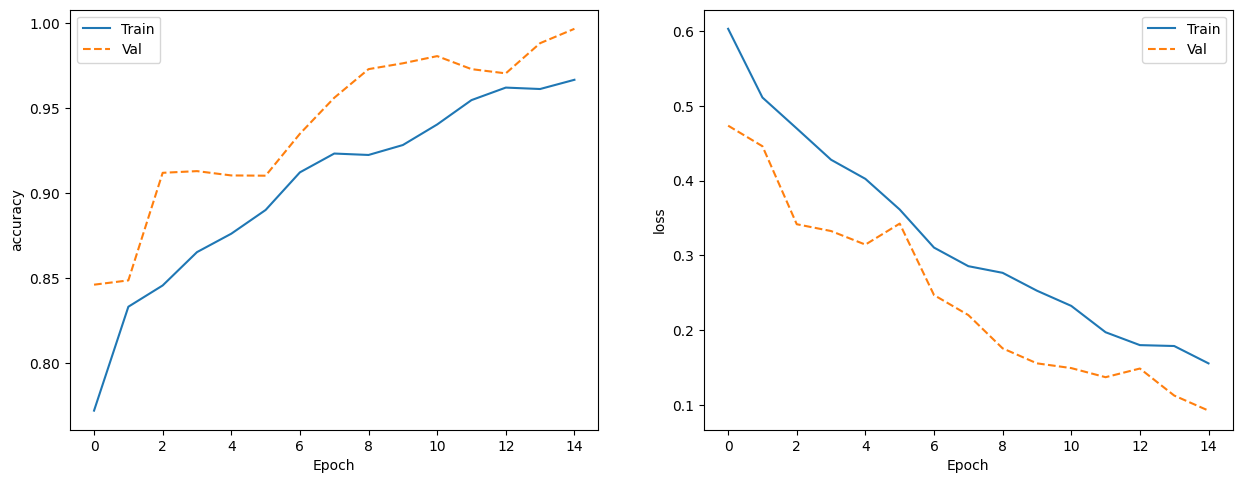

In [ ]:
plot_his(history)

In [ ]:
model.evaluate(test_ds)

15/15 ━━━━━━━━━━━━━━━━━━━━ 65s 4s/step - accuracy: 0.8236 - binary_crossentropy: 0.7798 - loss: 0.8525


/usr/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


[0.8068606853485107, 0.734132707118988, 0.8365591168403625]

15/15 ━━━━━━━━━━━━━━━━━━━━ 58s 4s/step
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       231
           1       0.85      0.82      0.84       234

    accuracy                           0.84       465
   macro avg       0.84      0.84      0.84       465
weighted avg       0.84      0.84      0.84       465



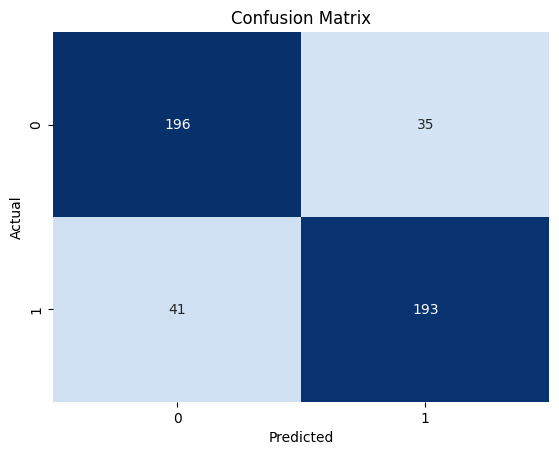

In [ ]:
plot_conf_matrix(model)

In [ ]:
best_model = keras.models.load_model("/content/effnet-ep15-loss0.020.keras")

In [ ]:
best_model.evaluate(test_ds)

15/15 ━━━━━━━━━━━━━━━━━━━━ 68s 3s/step - accuracy: 0.8236 - binary_crossentropy: 0.7798 - loss: 0.8525


[0.8068606853485107, 0.734132707118988, 0.8365591168403625]

15/15 ━━━━━━━━━━━━━━━━━━━━ 75s 5s/step
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       231
           1       0.85      0.82      0.84       234

    accuracy                           0.84       465
   macro avg       0.84      0.84      0.84       465
weighted avg       0.84      0.84      0.84       465



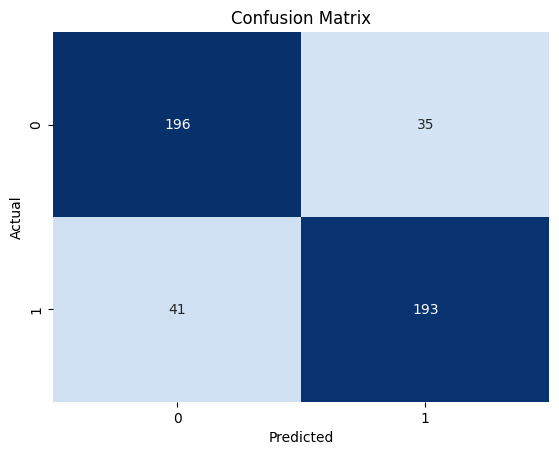

In [ ]:
plot_conf_matrix(best_model)

In [ ]:
import shutil
def Copy_Model(source_path, name):
    destination_path = f"/content/sample_data/{name}.keras"
    shutil.copyfile(source_path, destination_path)
    return destination_path

### Evaluating on loaded model

In [ ]:
prefix = '/kaggle/input/better-mura/MURA-v1.1/'
valid_data = pd.read_csv('/kaggle/input/better-mura/MURA-v1.1/MURA-v1.1/valid.csv')
# valid_data = valid_data[valid_data["BodyPart"].str.contains(r"XR_SHOULDER")]
# valid_data = valid_data[valid_data["BodyPart"].str.contains(r"XR")]
valid_data = valid_data[valid_data["BodyPart"] == "XR_ELBOW"]
paths = prefix + valid_data['path'].astype(str)
labels = valid_data['label']
labels = pd.Series(labels, name='Label')
labels = labels.astype(str)
v_images = pd.concat([paths, labels], axis=1)

In [ ]:
def load_image(image_path):
    img = tf.io.read_file(image_path)
    img = tf.io.decode_png(img, channels=3)
    img = tf.image.resize(img, (224, 224))
    return img

In [ ]:
def elbow_Predict(img):
    img = np.expand_dims(img, 0).astype(np.float32)
    prediction = model.predict(img, verbose = 0)
    binary_prediction = "Fractured" if prediction > 0.1 else "Non-Fractured"
    return binary_prediction

In [ ]:
from sklearn.metrics import cohen_kappa_score

fracturedcounter = 0
normalcounter = 0
prefracturedcounter = 0
prenormalcounter = 0
true_positive = 0
false_positive = 0
false_negative = 0
true_negative = 0

# Arrays to store actual and predicted labels
actual_labels = []
predicted_labels = []

for index, row in v_images.iterrows():
    image_path = row["path"]
    if row["Label"] == '1':
        label = "Fractured"
        fracturedcounter += 1
    else:
        label = "Non-Fractured"
        normalcounter += 1

    # Append actual label to the list
    actual_labels.append(label)

    img = load_image(image_path)

    ## PUT YOUR FUNCTION HERE ##
    prediction = elbow_Predict(img)

    # Append predicted label to the list
    predicted_labels.append(prediction)

    if prediction == "Fractured":
        prefracturedcounter += 1
    else:
        prenormalcounter += 1

    if label == prediction:
        if label == "Fractured":
            true_positive += 1
        else:
            true_negative += 1
    else:
        if label == "Fractured":
            false_negative += 1
        else:
            false_positive += 1

# Calculate performance metrics
accuracy = (true_positive + true_negative) / (true_positive + true_negative + false_positive + false_negative)
precision = true_positive / (true_positive + false_positive)
recall = true_positive / (true_positive + false_negative)
f1_score = 2 * (precision * recall) / (precision + recall)

# Calculate Cohen's Kappa score
kappa_score = cohen_kappa_score(actual_labels, predicted_labels)

print("Fractured Count: " + str(fracturedcounter) + " Normal Count: " + str(normalcounter))
print("preFractured Count: " + str(prefracturedcounter) + " preNormal Count: " + str(prenormalcounter))
print("Accuracy: ", accuracy * 100)
print("Precision: ", precision * 100)
print("Recall: ", recall * 100)
print("F1 Score: ", f1_score * 100)
print("Cohen's Kappa Score: ", kappa_score)


Fractured Count: 234 Normal Count: 231
preFractured Count: 251 preNormal Count: 214
Accuracy:  82.15053763440861
Precision:  80.0796812749004
Recall:  85.8974358974359
F1 Score:  82.88659793814433
Cohen's Kappa Score:  0.6428273966517671


## Testing different Thresholds

In [ ]:
def plot_conf_matrix_th(model, th):
    y_test = np.concatenate([y for x, y in test_ds], axis=0)

    y_pred = (model.predict(test_ds) > th)

    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, vmin=0, fmt='g', cmap='Blues', cbar=False)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix")
    plt.show()

15/15 ━━━━━━━━━━━━━━━━━━━━ 47s 3s/step
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       231
           1       0.85      0.82      0.84       234

    accuracy                           0.84       465
   macro avg       0.84      0.84      0.84       465
weighted avg       0.84      0.84      0.84       465



/usr/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


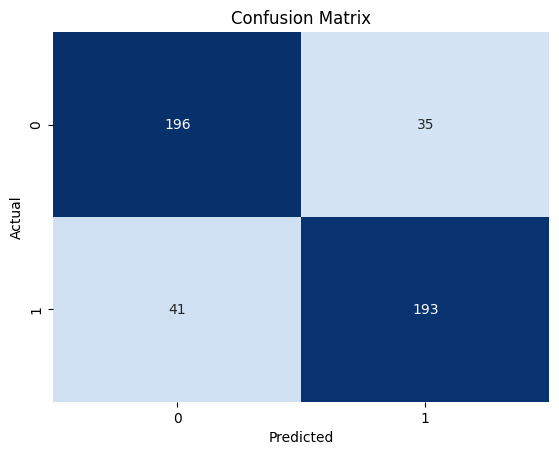

In [ ]:
plot_conf_matrix_th(best_model, th=.50)